# Scenario & Cost-Sensitivity Analysis — Week 3

Simulates three cleaning strategies (fixed-interval, image-only,
image+weather+cost) against a cited-soiling-rate dust model, on two real
Sunly Solar installations (5.2kW and 8kW, both net-metered, Karachi).

Illustrative simulation, not measured field data. Cleaning is DIY
(pressure washer, <15 min), not a paid service.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

print("Ready.")

Ready.


## 1. Real-data-grounded assumptions

System specs from the Solarman app and on-site K-Electric bills. Tariffs
are real numbers: Rs 34.53/kWh import rate and Rs 22.42/kWh net-metering
export rate, both read directly off real May 2026 bills. Cleaning costs
reflect DIY pressure-washing (<15 min) — water is the dominant real cost.

### Cleaning cost formula (generalizable)

`cleaning_cost = water_cost + electricity_cost + time_value`, where
`electricity_cost = power_rating_kW x duration_hours x tariff_rate_pkr_per_kwh`.

This formula generalizes beyond this project's DIY residential case —
substitute a farm-scale motorized cleaner's own power rating and applicable
tariff to reuse the same structure at a different scale.

For THIS project: real DIY pressure washer, **1100W** (1.1kW), under 15
minutes runtime, priced at the real residential tariff (Rs 34.53/kWh):

    electricity_cost = 1.1 kW x 0.25 hr x Rs 34.53/kWh =~ Rs 9.5
    (roughly Rs 3-10 across a 5-15 minute range)

Small relative to water + time, so it barely moves the existing DIY
brackets (Rs 50/150/300) — but it's now itemized rather than folded
silently into one guessed number. A 4th bracket, `paid_service`
(Rs 2,543 — a real quote of Rs 2,500 labor + owner-provided water/
electricity), is added below for comparison against a real paid
alternative to DIY.

In [2]:
# System specs (real, from Solarman app + on-site bills)
# Import rates are SYSTEM-SPECIFIC (confirmed via real bills, 3 Sep 2026):
#   - Ali: billed via BTK Electricity (Bahria Town Karachi's own distribution
#     entity), which sources bulk power from K-Electric but bills residents
#     at its own rate - Rs 84.96/kWh (from his bill's K-1 section).
#   - Amir: billed directly by K-Electric - Rs 34.53/kWh (his bill's
#     Variable Off Peak rate).
# These are genuinely different real tariffs, not a data error.
SYSTEMS = {
    "Ali_5.2kW": {
        "capacity_kw": 5.2,
        "location": (25.061328, 67.315913),  # Bahria Town, Karachi
        "net_metered": True,
        "capacity_scale": 1.0,   # baseline - Ali's real observed yield is the reference profile
        "import_rate_pkr_per_kwh": 84.96,  # BTK Electricity's real rate, from his bill's K-1 section
    },
    "Amir_8kW": {
        "capacity_kw": 8.0,
        "location": (24.936833, 67.062083),
        "net_metered": True,
        "capacity_scale": 8.0 / 5.2,  # proxy scaling from Ali's profile - no raw chart for Amir yet, flag in methods
        "import_rate_pkr_per_kwh": 34.53,  # Amir's real K-Electric off-peak rate
    },
}

# Export/net-metering rate - kept SHARED across both systems. This is a
# NEPRA-regulated national figure (not distributor-specific): Ali's bill
# states it explicitly (NEPRA-PPA RATE = 22.42), and Amir's bill cites the
# same regulatory framework (SRO 547/2026, Prosumer Regulations 2026) in
# its message board, so applying it to both is reasonable and documented -
# not separately confirmed on Amir's bill line-by-line, flagged as an
# assumption.
EXPORT_RATE_OLD_REGIME = 22.42    # Ali's bill, explicit NEPRA-PPA rate (grandfathered agreements)
EXPORT_RATE_NEW_REGIME = 13.0     # midpoint of the new net billing bracket (Rs 11-15/kWh)

# Soiling rate assumptions (cited, not invented)
SOILING_RATE_LOW = 0.003    # 0.3%/day  (NREL typical low end)
SOILING_RATE_MID = 0.008    # 0.8%/day  (Ghazi et al., Lahore - primary)
SOILING_RATE_HIGH = 0.019   # 1.9%/day  (Cyprus arid seasonal average)

# Cleaning cost assumptions - DIY pressure-washer, under 15 min total.
# Each DIY bracket = water + electricity + time value, itemized below.
# Electricity uses the REAL pressure washer spec (1100W). For the DIY
# brackets below, electricity is costed at Amir's rate (34.53) as a
# representative example - the per-system rates above are used for the
# actual soiling-LOSS valuation in the simulation, not for this small
# fixed illustrative electricity line.
PRESSURE_WASHER_KW = 1.1  # real spec: 1100W

CLEANING_COST_LOW_PKR = 50      # water ~40 + electricity ~3 (5 min) + time ~0
CLEANING_COST_MID_PKR = 150     # water ~135 + electricity ~6 (10 min) + modest time value
CLEANING_COST_HIGH_PKR = 300    # water ~280 + electricity ~10 (15 min) + higher time value + minor wear

# Real paid-service quote, added as a 4th bracket for comparison.
# Rs 2,500/session (labor only - water/electricity provided by homeowner).
CLEANING_COST_PAID_SERVICE_PKR = 2500 + 43   # = 2543

print("Constants loaded.")
print(f"Systems: {list(SYSTEMS.keys())}")
ali_rate = SYSTEMS["Ali_5.2kW"]["import_rate_pkr_per_kwh"]
print(f"Ali import rate: {ali_rate} PKR/kWh")
amir_rate = SYSTEMS["Amir_8kW"]["import_rate_pkr_per_kwh"]
print(f"Amir import rate: {amir_rate} PKR/kWh")
print(f"Paid-service bracket: {CLEANING_COST_PAID_SERVICE_PKR} PKR")

Constants loaded.
Systems: ['Ali_5.2kW', 'Amir_8kW']
Ali import rate: 84.96 PKR/kWh
Amir import rate: 34.53 PKR/kWh
Paid-service bracket: 2543 PKR


### Customizing these assumptions for reproducibility

Every constant above is a standalone parameter — swap in your own numbers
to reproduce this analysis for a different location, tariff, or cleaning
method without touching the simulation logic below:

- `IMPORT_RATE_PKR_PER_KWH` / `EXPORT_RATE_*` — your local tariff/bill
- `PRESSURE_WASHER_KW` — rating of whatever cleaning equipment is used
  (this formula scales to farm-size motorized cleaners too — see Section 1)
- `SOILING_RATE_*` — cited soiling-rate literature for your region
- `CLEANING_COST_*_PKR` — DIY brackets, or `CLEANING_COST_PAID_SERVICE_PKR`
  for a real paid-service quote in your area

The simulation grid (Section 3) automatically loops over whatever cost
brackets and soiling rates are defined here — no changes needed elsewhere
in the notebook.

## 2. Simulation engine

Dust accumulates daily at the cited soiling rate and partially clears on
rain days (a fraction, not a full reset — rain is a soft signal only). A
simulated daily photo flags "dusty" once accumulated loss crosses a 3%
detectability threshold. Three strategies compete on the same simulated
conditions:

- **fixed_interval** — clean every 14 days regardless of condition
- **image_only** — clean immediately whenever "dusty" is detected
- **image_weather_cost** — only clean once accumulated $ loss since the
  last cleaning actually exceeds the cleaning cost

Daily yield is drawn from Ali's real observed monthly ranges (Solarman
app), scaled by capacity for Amir's system.

In [3]:
import zlib

def scenario_seed(system_name, soiling_label, cost_label, strategy):
    """Deterministic per-scenario seed - independent of loop order, so
    adding/removing cost brackets or reordering scenarios never silently
    changes other scenarios' random draws. Uses crc32 (not hash()) since
    Python's built-in hash() is randomized per-process for strings."""
    key = f"{system_name}|{soiling_label}|{cost_label}|{strategy}"
    return zlib.crc32(key.encode()) % (2**31)


def simulate_daily_yield(rng, month, capacity_scale=1.0):
    """Draw one day's generation (kWh) from Ali's real observed monthly range,
    scaled by capacity ratio if simulating a different system."""
    ranges = {
        "Jun": (7, 33),
        "Jul": (1, 27),   # monsoon core
        "Aug": (2, 26),
    }
    low, high = ranges[month]
    return rng.uniform(low, high) * capacity_scale


def simulate_rain_day(rng, month):
    """Illustrative monthly rain probability, inferred from the sharp dips
    observed in the real Solarman charts (not measured rainfall data -
    a simplification, flagged clearly here and in methods)."""
    probs = {"Jun": 0.15, "Jul": 0.30, "Aug": 0.20}
    return rng.random() < probs[month]


def run_strategy(strategy, n_days, capacity_scale, soiling_rate, cleaning_cost,
                  economic_rate, seed, detect_threshold=0.03, fixed_interval_days=14,
                  rain_clear_fraction=0.3):
    """
    Simulates one strategy over n_days for one system.
    Uses its own local random.Random(seed) instance - fully independent of
    any other scenario's draws, regardless of execution order.
    Returns: total cleaning cost, total residual soiling loss (PKR), n_cleanings
    """
    import random as _random_module
    rng = _random_module.Random(seed)

    months_cycle = ["Jun", "Jul", "Aug"]
    dust_fraction = 0.0
    days_since_clean = 0
    accumulated_loss_pkr_since_clean = 0.0

    total_cleaning_cost = 0.0
    total_residual_loss_pkr = 0.0
    n_cleanings = 0

    for day in range(n_days):
        month = months_cycle[(day // 30) % len(months_cycle)]
        daily_kwh = simulate_daily_yield(rng, month, capacity_scale)
        is_rain = simulate_rain_day(rng, month)

        dust_fraction += soiling_rate
        if is_rain:
            dust_fraction *= (1 - rain_clear_fraction)
        dust_fraction = min(dust_fraction, 0.5)

        daily_loss_kwh = daily_kwh * dust_fraction
        daily_loss_pkr = daily_loss_kwh * economic_rate

        total_residual_loss_pkr += daily_loss_pkr
        accumulated_loss_pkr_since_clean += daily_loss_pkr
        days_since_clean += 1

        classifier_says_dusty = dust_fraction >= detect_threshold

        should_clean = False
        if strategy == "fixed_interval":
            should_clean = days_since_clean >= fixed_interval_days
        elif strategy == "image_only":
            should_clean = classifier_says_dusty
        elif strategy == "image_weather_cost":
            should_clean = classifier_says_dusty and (accumulated_loss_pkr_since_clean >= cleaning_cost)

        if should_clean:
            total_cleaning_cost += cleaning_cost
            n_cleanings += 1
            dust_fraction = 0.0
            days_since_clean = 0
            accumulated_loss_pkr_since_clean = 0.0

    return {
        "strategy": strategy,
        "total_cleaning_cost_pkr": round(total_cleaning_cost, 0),
        "total_residual_loss_pkr": round(total_residual_loss_pkr, 0),
        "total_cost_pkr": round(total_cleaning_cost + total_residual_loss_pkr, 0),
        "n_cleanings": n_cleanings,
    }

print("Simulation engine defined (deterministic per-scenario seeding).")

Simulation engine defined (deterministic per-scenario seeding).


## 3. Run the full sensitivity grid

2 systems x 3 soiling rates x 4 cleaning-cost brackets x 3 strategies =
72 runs (24 scenarios), valued at the import rate (upper bound). Each
scenario uses its own deterministic seed (derived from its own parameters,
not shared global random state), so results are stable regardless of
what order scenarios run in or how many brackets are defined.

In [4]:
import pandas as pd

N_DAYS = 90  # roughly one full Jun-Jul-Aug cycle
results = []

COST_BRACKETS = [
    ("low", CLEANING_COST_LOW_PKR),
    ("mid", CLEANING_COST_MID_PKR),
    ("high", CLEANING_COST_HIGH_PKR),
    ("paid_service", CLEANING_COST_PAID_SERVICE_PKR),
]

for system_name, system in SYSTEMS.items():
    for soiling_label, soiling_rate in [("low", SOILING_RATE_LOW), ("mid", SOILING_RATE_MID), ("high", SOILING_RATE_HIGH)]:
        for cost_label, cleaning_cost in COST_BRACKETS:
            for strategy in ["fixed_interval", "image_only", "image_weather_cost"]:
                seed = scenario_seed(system_name, soiling_label, cost_label, strategy)
                r = run_strategy(
                    strategy=strategy,
                    n_days=N_DAYS,
                    capacity_scale=system["capacity_scale"],
                    soiling_rate=soiling_rate,
                    cleaning_cost=cleaning_cost,
                    economic_rate=system["import_rate_pkr_per_kwh"],  # system-specific: Ali 84.96, Amir 34.53
                    seed=seed,
                )
                r.update({
                    "system": system_name,
                    "soiling_rate": soiling_label,
                    "cleaning_cost_bracket": cost_label,
                })
                results.append(r)

df = pd.DataFrame(results)
df = df[["system", "soiling_rate", "cleaning_cost_bracket", "strategy",
         "n_cleanings", "total_cleaning_cost_pkr", "total_residual_loss_pkr", "total_cost_pkr"]]

print(f"Total scenarios run: {len(df)}")
df.head(20)

Total scenarios run: 72


,system,soiling_rate,cleaning_cost_bracket,strategy,n_cleanings,total_cleaning_cost_pkr,total_residual_loss_pkr,total_cost_pkr
0,Ali_5.2kW,low,low,fixed_interval,6,300.0,1854.0,2154.0
1,Ali_5.2kW,low,low,image_only,3,150.0,2239.0,2389.0
2,Ali_5.2kW,low,low,image_weather_cost,5,250.0,1992.0,2242.0
3,Ali_5.2kW,low,mid,fixed_interval,6,900.0,2018.0,2918.0
4,Ali_5.2kW,low,mid,image_only,4,600.0,2012.0,2612.0
5,Ali_5.2kW,low,mid,image_weather_cost,5,750.0,2102.0,2852.0
6,Ali_5.2kW,low,high,fixed_interval,6,1800.0,1685.0,3485.0
7,Ali_5.2kW,low,high,image_only,3,900.0,2110.0,3010.0
8,Ali_5.2kW,low,high,image_weather_cost,5,1500.0,2177.0,3677.0
9,Ali_5.2kW,low,paid_service,fixed_interval,6,15258.0,1942.0,17200.0


## 4. Summarize: which strategy wins?

Result (import-rate valuation, system-specific tariffs - Ali at Rs 84.96/kWh
via BTK Electricity, Amir at Rs 34.53/kWh via K-Electric direct):
image_weather_cost wins 15/24 scenarios (62.5%), lowest average total cost
overall (Rs 6,640 vs Rs 9,724 fixed-interval vs Rs 18,646 image-only).
Ali's totals are notably higher than Amir's throughout, reflecting his
real ~2.45x higher per-kWh rate - a genuine finding, not noise: the same
soiling loss costs Ali substantially more in practice. The gap between
strategies widens sharply once the paid_service bracket is included -
image_only triggers the expensive Rs 2,543 service on every detection
with no cost-awareness, while image_weather_cost properly defers until
it's actually worth paying for.

In [5]:
winners = df.loc[df.groupby(["system", "soiling_rate", "cleaning_cost_bracket"])["total_cost_pkr"].idxmin()]
winners = winners[["system", "soiling_rate", "cleaning_cost_bracket", "strategy", "total_cost_pkr"]]

n_scenarios = len(SYSTEMS) * 3 * len(COST_BRACKETS)
n_runs = n_scenarios * 3  # x3 strategies

print(f"Winning strategy per scenario ({n_scenarios} scenarios total, {len(SYSTEMS)} systems x 3 soiling rates x {len(COST_BRACKETS)} cost brackets):")
print(winners.to_string(index=False))

print(f"\n--- Win counts across all {n_scenarios} scenarios ---")
print(winners["strategy"].value_counts())

print(f"\n--- Average total cost by strategy, across ALL {n_runs} runs ---")
print(df.groupby("strategy")["total_cost_pkr"].mean().round(0).sort_values())

Winning strategy per scenario (24 scenarios total, 2 systems x 3 soiling rates x 4 cost brackets):
   system soiling_rate cleaning_cost_bracket           strategy  total_cost_pkr
Ali_5.2kW         high                  high image_weather_cost         10942.0
Ali_5.2kW         high                   low         image_only          5310.0
Ali_5.2kW         high                   mid image_weather_cost          8757.0
Ali_5.2kW         high          paid_service image_weather_cost         26522.0
Ali_5.2kW          low                  high         image_only          3010.0
Ali_5.2kW          low                   low     fixed_interval          2154.0
Ali_5.2kW          low                   mid         image_only          2612.0
Ali_5.2kW          low          paid_service image_weather_cost          5561.0
Ali_5.2kW          mid                  high image_weather_cost          6047.0
Ali_5.2kW          mid                   low image_weather_cost          3194.0
Ali_5.2kW          mi

## 5. Robustness check: lower-bound (export-rate) valuation

Re-runs the same 24 scenarios valuing lost generation at the export rate
as a lower bound (shared across both systems - a NEPRA-regulated national
figure, not distributor-specific). Result: the conclusion holds and gets
*stronger* - image_weather_cost wins 20/24 (83%), avg cost Rs 3,627 vs
Rs 6,686 fixed-interval vs Rs 16,530 image-only. 9/24 scenario winners
flip between the two bounds, mostly in Ali's DIY low/mid brackets where
his much higher import rate makes the two bounds diverge more than
Amir's; the paid_service bracket is stable across both bounds for both
systems - image_weather_cost wins there consistently.

In [6]:
results_lowerbound = []

for system_name, system in SYSTEMS.items():
    for soiling_label, soiling_rate in [("low", SOILING_RATE_LOW), ("mid", SOILING_RATE_MID), ("high", SOILING_RATE_HIGH)]:
        for cost_label, cleaning_cost in COST_BRACKETS:
            for strategy in ["fixed_interval", "image_only", "image_weather_cost"]:
                # different seed namespace (prefix) so this doesn't reuse the same
                # random draws as the import-rate run above
                seed = scenario_seed("EXPORT_" + system_name, soiling_label, cost_label, strategy)
                r = run_strategy(
                    strategy=strategy, n_days=N_DAYS,
                    capacity_scale=system["capacity_scale"],
                    soiling_rate=soiling_rate, cleaning_cost=cleaning_cost,
                    economic_rate=EXPORT_RATE_OLD_REGIME,
                    seed=seed,
                )
                r.update({"system": system_name, "soiling_rate": soiling_label, "cleaning_cost_bracket": cost_label})
                results_lowerbound.append(r)

df_lower = pd.DataFrame(results_lowerbound)

winners_lower = df_lower.loc[df_lower.groupby(["system", "soiling_rate", "cleaning_cost_bracket"])["total_cost_pkr"].idxmin()]

print("--- Win counts, EXPORT rate (lower bound) ---")
print(winners_lower["strategy"].value_counts())

print("\n--- Average total cost by strategy, EXPORT rate ---")
print(df_lower.groupby("strategy")["total_cost_pkr"].mean().round(0).sort_values())

print("\n--- Compare: did the winner change in any scenario vs. the import-rate run? ---")
comparison = winners[["system","soiling_rate","cleaning_cost_bracket","strategy"]].reset_index(drop=True)
comparison_lower = winners_lower[["system","soiling_rate","cleaning_cost_bracket","strategy"]].reset_index(drop=True)
comparison["strategy_export_rate"] = comparison_lower["strategy"]
comparison["changed"] = comparison["strategy"] != comparison["strategy_export_rate"]
print(comparison.to_string(index=False))

n_scenarios = len(SYSTEMS) * 3 * len(COST_BRACKETS)
print(f"\nScenarios where the winning strategy changed: {comparison['changed'].sum()} / {n_scenarios}")

--- Win counts, EXPORT rate (lower bound) ---
strategy
image_weather_cost    20
fixed_interval         2
image_only             2
Name: count, dtype: int64

--- Average total cost by strategy, EXPORT rate ---
strategy
image_weather_cost     3627.0
fixed_interval         6686.0
image_only            16530.0
Name: total_cost_pkr, dtype: float64

--- Compare: did the winner change in any scenario vs. the import-rate run? ---
   system soiling_rate cleaning_cost_bracket           strategy strategy_export_rate  changed
Ali_5.2kW         high                  high image_weather_cost       fixed_interval     True
Ali_5.2kW         high                   low         image_only   image_weather_cost     True
Ali_5.2kW         high                   mid image_weather_cost   image_weather_cost    False
Ali_5.2kW         high          paid_service image_weather_cost   image_weather_cost    False
Ali_5.2kW          low                  high         image_only   image_weather_cost     True
Ali_5.2kW 

## 6. Figure: average total cost by strategy

Grouped bar chart for the paper/poster, both economic bounds side by side.

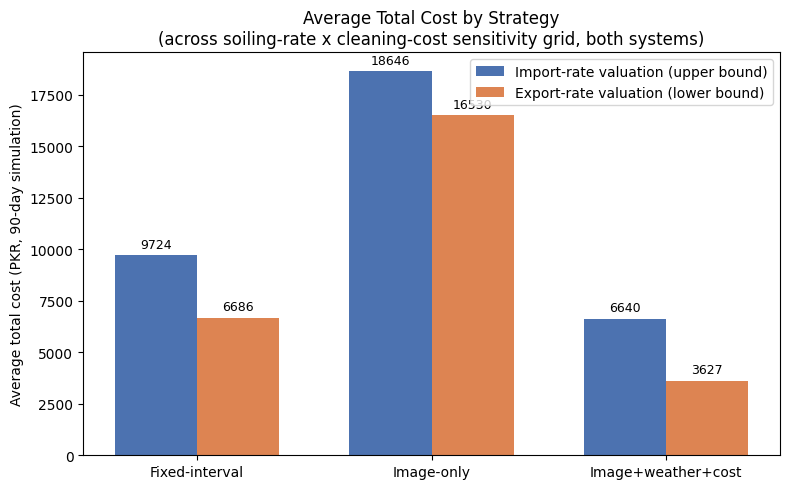

Saved as strategy_comparison.png - download from the Colab file browser.


In [7]:
strategies = ["fixed_interval", "image_only", "image_weather_cost"]
strategy_labels = ["Fixed-interval", "Image-only", "Image+weather+cost"]

avg_import = [df[df["strategy"] == s]["total_cost_pkr"].mean() for s in strategies]
avg_export = [df_lower[df_lower["strategy"] == s]["total_cost_pkr"].mean() for s in strategies]

x = np.arange(len(strategies))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, avg_import, width, label="Import-rate valuation (upper bound)", color="#4C72B0")
bars2 = ax.bar(x + width/2, avg_export, width, label="Export-rate valuation (lower bound)", color="#DD8452")

ax.set_ylabel("Average total cost (PKR, 90-day simulation)")
ax.set_title("Average Total Cost by Strategy\n(across soiling-rate x cleaning-cost sensitivity grid, both systems)")
ax.set_xticks(x)
ax.set_xticklabels(strategy_labels)
ax.legend()
ax.bar_label(bars1, fmt="%.0f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.0f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("strategy_comparison.png", dpi=150)
plt.show()

print("Saved as strategy_comparison.png - download from the Colab file browser.")